# Chapter 3 : 신경망
##학습내용
### 신경망, 활성화 함수애 대해서도 공부한다. 손글씨 숫자 인식 예제를 통해 신경망을 구현한다.

# 3.1 퍼셉트론에서 신경망으로
## 3.1.1 신경망의 예
### 예) 2층 신경망
- **입력층(0층)** : 가장왼쪽
- **은닉층(1층)** : 중간
- **출력층(2층)** : 가장 오른쪽
> **2층 신경망**이라고함 -> 가중치를 가지는층이 2층이라서
>
> 주의 : 문헌에 따라 다름

## 3.1.2 퍼셉트론 복습

$$
y = \begin{cases}
0 & (w_1x_1 + w_2x_2 + b \le 0) \\
1 & (w_1x_1 + w_2x_2 + b > 0)
\end{cases}
$$

- $b$ : 편향을 나타내는 매개변수
- 기존 퍼셉트론 그림은 편향이 표시되지 않음 퍼셉트론 그림에 편향을 넣으려면?
> 입력이 항상1이고 가중치가 $b$인 뉴런을 추가

### 이런식으로도 나타낼 수 있다.

$$y = h(b + w_1x_1 + w_2x_2)$$
$$
h(x) = \begin{cases}
0 & (x \le 0) \\
1 & (x > 0)
\end{cases}
$$

## 3.1.3 활성화 함수의 등장
### 활성화 함수 activation function
- 입력신호의 총합을 출력신호로 변환하는 함수 (여기서는 h(x))

> 1단계
> $$ a = b + w_1x_1 + w_2x_2 $$
> 2단계
> $$ y = h(a) $$

표기 : 뉴런 == 노드, 뉴런안에 활성화 함수의 처리과정을 그려 자세히 표현하기도 함

# 3.2 활성화 함수
## 3.2.1 시그모이드 함수 Sigmoid function

$$ h(x) = \frac{1}{1 + \exp(-x)} $$

- $\exp(-x)$ 는 $e^{-x}$를 나타냄

##3.2.2 계단함수 구현하기
### 계단함수 step funtion
- 입계값을 기준으로 출력이 바뀌는 함수

In [27]:
def step_funtion(x):
  if x > 0:
    return 1
  else:
    return 0

# 실수만 받을 수 있음

In [28]:
# numpy를 이용하기 위해 코드를 살짝 바꾸면?
def stpe_function(x):
  y = x > 0
  return y.astype(int)

In [29]:
# 함수가 동작하는 원리
import numpy as np
x = np.array([-1.0, 1.0, 2.0])
y = x > 0 # y = array([False, True, True]) : bool 타입 array
y.astype(int) # 정수로 변환

array([0, 1, 1])

## 3.2.3 계단 함수의 그래프

- x = 0 에서 그래프의 값이 바뀜

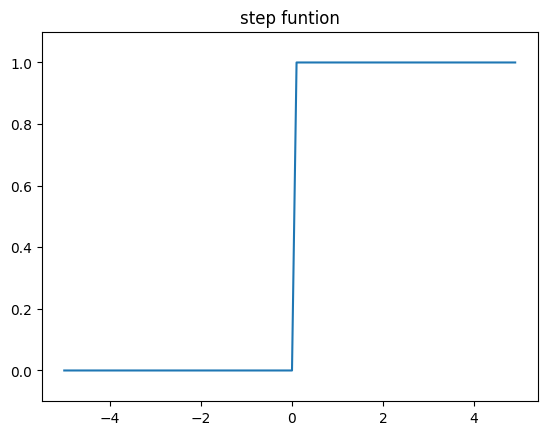

In [30]:
import numpy as np
import matplotlib.pyplot as plt

def step_funtion(x):
  return np.array(x > 0, dtype=int)

x = np.arange(-5.0, 5.0, 0.1)
y = step_funtion(x)
plt.title("step funtion")
plt.plot(x, y)
plt.ylim(-0.1, 1.1)
plt.show()

## 3.2.4 시그모이드 함수 구현하기
- numpy의 브로드캐스트 기능을 이용하여 구현

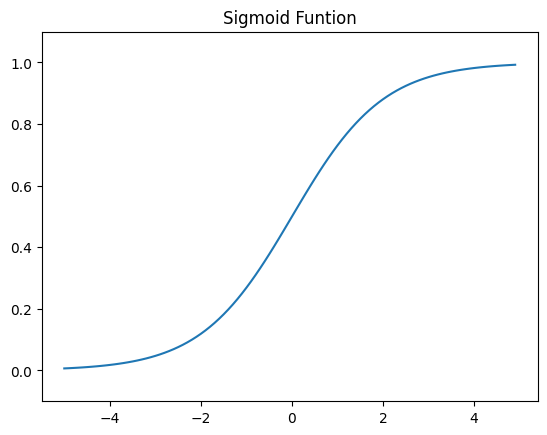

In [31]:
def sigmoid(x):
  return 1 / (1 + np.exp(-x))

x = np.array([-1.0, 1.0, 2.0])
sigmoid(x)

x = np.arange(-5.0, 5.0, 0.1)
y = sigmoid(x)
plt.title("Sigmoid Funtion")
plt.plot(x, y)
plt.ylim(-0.1, 1.1)
plt.show()

## 3.2.5 시그모이드 함수와 계단 함수 비교

- "매끄러움"의 차이 : 실수를 전달하는 시그모이드 함수
- 공통점
  - 최소 0, 최대 1
  - 입력이 작으면 0에 가까움, 크면 1에 가까움
  - 입력이 뭐든 간에 0과1 사이의 수로 변환하는 함수

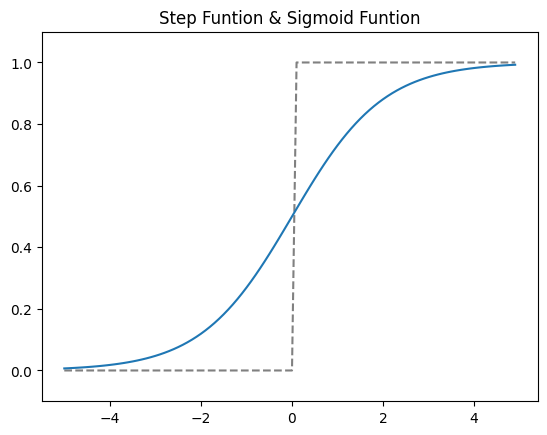

In [32]:
x = np.arange(-5.0, 5.0, 0.1)

step_y = step_funtion(x)
sig_y = sigmoid(x)

plt.title("Step Funtion & Sigmoid Funtion")
plt.plot(x, step_y, '--', color="gray")
plt.plot(x, sig_y, '-')
plt.ylim(-0.1, 1.1)
plt.show()

## 3.2.6 비선형 함수

### 신경망에서는 비선형 함수를 이용해야 이점을 가진다.
- 선형함수를 이용한다면?
> $ h(x) = cx $를 사용한 3층 네트워크
>
> $ y(x) = h(h(h(x))) = c^3x = ax $
>
> 즉, 의미가 없다.

## 3.2.7 ReLU 함수
- 입력이 0을 넘으면 그대로, 0이하면 0을 출력

$$
h(x) = \begin{cases}
x & (x > 0)\\
0 & (x \le 0 )
\end{cases}
$$

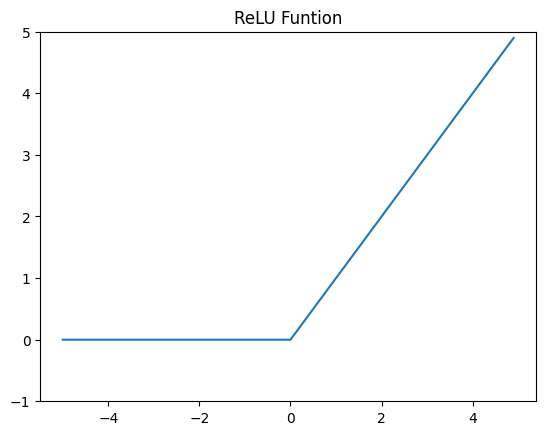

In [33]:
def relu(x):
  return np.maximum(0, x)

x = np.arange(-5.0, 5.0, 0.1)
y = relu(x)
plt.title("ReLU Funtion")
plt.plot(x, y)
plt.ylim(-1, 5)
plt.show()

# 3.3 다차원 배열의 계산
## 3.3.1 다차원 배열


In [34]:
import numpy as np
A = np.array([1, 2, 3, 4])
print(A)
np.ndim(A) # 배열의 차원 수 확인
A.shape # 배열의 형상 확인, 튜플을 반환한다는 점 주의
A.shape[0]

[1 2 3 4]


4

In [35]:
B = np.array([[1, 2], [3, 4], [5, 6]])
print(B)
np.ndim(B)
B.shape

[[1 2]
 [3 4]
 [5 6]]


(3, 2)

## 3.3.2 행렬의 곱
### 행렬 - 2차원 배열
- **행(row)** : 가로방향
- **열(column)** : 세로방향

### 2 x 2 행렬의 곱

$$
A = \begin{pmatrix}
1 & 2 \\
3 & 4
\end{pmatrix}
,
B = \begin{pmatrix}
5 & 6 \\
7 & 8
\end{pmatrix}
,
\begin{pmatrix}
1 & 2 \\
3 & 4
\end{pmatrix}
\begin{pmatrix}
5 & 6 \\
7 & 8
\end{pmatrix}
=
\begin{pmatrix}
19 & 22 \\
43 & 50
\end{pmatrix}
$$
- 행,열 순서로 곱하면 됨
- 예) A의 1행, B의 1열 1x5 + 2x7 = 19 -> 1행 1열의 값은 19
- A의 i행, B의 j행 -> 새로운 행렬의 i행, j열의 값

> 행렬의 곱은 np.dot()을 이용
>
> 교환법칙 성립 안함

In [36]:
A = np.array([[1, 2], [3, 4]])
print(A.shape)

B = np.array([[5, 6], [7, 8]])
print(B.shape)

np.dot(A, B)

(2, 2)
(2, 2)


array([[19, 22],
       [43, 50]])

### 2 x 3 행렬, 3 x 2 행렬의 곱

In [37]:
A = np.array([[1, 2, 3], [4, 5, 6]])
print(A.shape)

B = np.array([[1, 2], [3, 4], [5, 6]])
print(B.shape)

np.dot(A, B)

(2, 3)
(3, 2)


array([[22, 28],
       [49, 64]])

### 2 x 3, 2 x 2 행렬의 곱?

결과는?
- 불가능
- 대응하는 차원의 수를 일치시켜야함
- axb, bxc 이런식

In [38]:
C = np.array([[1, 2], [3, 4]])
print(C.shape)
print(A.shape)
# np.dot(A, C)

(2, 2)
(2, 3)


In [39]:
A = np.array([[1, 2], [3, 4], [5, 6]])
print(A.shape)
B = np.array([7, 8])
print(B.shape)
np.dot(A, B)

(3, 2)
(2,)


array([23, 53, 83])

## 3.3.3 신경망에서의 행렬곱

- 입력 : $x_1, x_2$
- 출력 : $y_1, y_2, y_3$
- 가중치 : $\begin{pmatrix} 1 & 3 & 5\\ 2 & 4 & 6 \end{pmatrix}$

$$ XW = Y $$

In [40]:
X = np.array([1, 2])
print(X.shape)

W = np.array([[1, 3, 5], [2, 4, 6]])
print(W.shape)

Y = np.dot(X, W)
print(Y)

(2,)
(2, 3)
[ 5 11 17]


# 3.4 3층 신경망 구현하기
- 입력층(0층) : 뉴런 2개
- 은닉층(1층) : 뉴런 3개
- 은닉층(2층) : 뉴런 2개
- 출력층(3층) : 뉴런 2개

## 3.4.1 표기법 설명
- 윗첨자 : n층의 가증치, 뉴런
- 아래첨자 : '다음층 번호, 앞 층 번호'
$$ w_{12}^{(1)} , a_1^{(1)}$$
예) 1층의 가중치, 다음층의 1번째 뉴런, 앞층의 2번째 뉴런 연결

## 3.4.2 각 층의 신호 전달 구현하기

$$ a_1^{(1)} = w_{11}^{(1)}x_1 + w_{12}^{(1)}x_2 + b_1^{(1)} $$
- 행렬의 곱을 이용하여 간소화
$$ A^{(1)} = XW^{(1)} + B^{(1)} $$
- 이때 행렬 $A^{(1)}, X, B^{(1)}, W^{(1)}$은 다음과 같다.

$$ A^{(1)} = \begin{pmatrix} a_1^{(1)} & a_2^{(1)} & a_3^{(1)} \end{pmatrix},
X = \begin{pmatrix} x_1 & x_2 \end{pmatrix},
B^{(1)} = \begin{pmatrix} b_1^{(1)} & b_2^{(1)} & b_3^{(1)} \end{pmatrix},
W^{(1)} = \begin{pmatrix}
W_{11}^{(1)} & W_{21}^{(1)} & W_{31}^{(1)}\\
W_{12}^{(1)} & W_{22}^{(1)} & W_{33}^{(1)}
\end{pmatrix}$$

In [41]:
# 입력에서 1층으로

X = np.array([1.0, 0.5])
W1 = np.array([[0.1, 0.3, 0.5], [0.2, 0.4, 0.6]])
B1 = np.array([0.1, 0.2, 0.3])

print(X.shape)
print(W1.shape)
print(B1.shape)

A1 = np.dot(X,W1) + B1

(2,)
(2, 3)
(3,)


- 활성화 함수 추가 : 시그모이드 함수

In [42]:
Z1 = sigmoid(A1)

print(A1)
print(Z1)

[0.3 0.7 1.1]
[0.57444252 0.66818777 0.75026011]


- 1층에서 2층으로

In [43]:
W2 = np.array([[0.1, 0.4], [0.2, 0.5], [0.3, 0.6]])
B2 = np.array([0.1, 0.2])

print(Z1.shape)
print(W2.shape)
print(B2.shape)

A2 = np.dot(Z1, W2) + B2
Z2 = sigmoid(A2)

(3,)
(3, 2)
(2,)


- 2층에서 3층으로
- 활성화 함수만 다름 : 값을 그대로쓰는 identity function

In [44]:
def identity_function(x):
  return x

W3 = np.array([[0.1, 0.3], [0.2, 0.4]])
B3 = np.array([0.1, 0.2])
A3 = np.dot(Z2, W3) + B3
Y = identity_function(A3)

## 3.4.3 구현정리
- init_network() : 가중치와 편향 초기화, network 딕셔너리에 저장

- forward() : 입력신호를 출력으로 변환하는 과정

In [45]:
def init_network():
  network = {}
  network['W1'] = np.array([[0.1, 0.3, 0.5], [0.2, 0.4, 0.6]])
  network['b1'] = np.array([0.1, 0.2, 0.3])
  network['W2'] = np.array([[0.1, 0.4], [0.2, 0.5], [0.3, 0.6]])
  network['b2'] = np.array([0.1, 0.2])
  network['W3'] = np.array([[0.1, 0.3], [0.2, 0.4]])
  network['b3'] = np.array([0.1, 0.2])

  return network

def forward(network, x):
  W1, W2, W3 = network['W1'], network['W2'], network[ 'W3']
  b1, b2, b3 = network['b1'], network['b2'], network['b3']

  a1= np.dot(x, W1) + b1
  z1 = sigmoid(a1)
  a2 = np.dot(z1, W2) + b2
  z2 = sigmoid(a2)
  a3= np.dot(z2, W3) + b3
  y = identity_function(a3)

  return y

network = init_network()
x = np.array([1.0, 0.5])
y = forward(network, x)
print(y) # [ 0.31682708 0.69627909]

[0.31682708 0.69627909]


# 3.5 출력층 설계하기
신경망은 일반적으로 분류와 회귀 다 사용가능, 활성화 함수가 달라질뿐
- 회귀(regression) : 항등함수
- 분류(classification) : 소프트맥스 함수

## 3.5.1 항등 함수와 소프트맥스 함수 구현하기
### 항등함수 identity function
- 입력을 그대로 출력

### 소프트맥스 함수 softmax function

- 분자 : 입력신호의 지수함수
- 분모 : 모든 입력신호의 지수함수 합

$$
y_k = \frac{\exp(a_k)}{\sum^{n}_{i=1} \exp(a_i)}
$$

In [46]:
# 소프트맥스 함수 개념이해
a = np.array([0.3, 2.9, 4.0])

exp_a = np.exp(a)
print(exp_a)

sum_exp_a = np.sum(exp_a)
print(sum_exp_a)

y = exp_a / sum_exp_a
print(y)

[ 1.34985881 18.17414537 54.59815003]
74.1221542101633
[0.01821127 0.24519181 0.73659691]


In [47]:
def softmax(a):
  exp_a = np.exp(a)
  sum_exp_a = np.sum(exp_a)
  y = exp_a / sum_exp_a

  return y

## 3.5.2 소프트맥스 함수 구현 시 주의점
- 오버플로우 문제가 일어난다.
- 지수 함수를 사용하기 때문에 값이 너무 커짐

### 개선
$$
y_k
= \frac{\exp(a_k)}{\sum^{n}_{i=1} \exp(a_i)}
= \frac{C\exp(a_k)}{C\sum^{n}_{i=1} \exp(a_i)}
= \frac{\exp(a_k + \log{C})}{\sum^{n}_{i=1} \exp(a_i + \log{C})}
= \frac{\exp(a_k + C')}{\sum^{n}_{i=1} \exp(a_i + C')}
$$

- C값을 분모 분자에 동시에 곱하기
- C'값이 뭐가 되든 상관없음
- C'값은 입력신호중 최댓값을 사용하는 것이 일반적

In [48]:
a = np.array([1010, 1000, 990])
print(np.exp(a) / np.sum(np.exp(a))) # 오버플로우 발생 - 제대로 계산이 안됨

c = np.max(a)
print(a - c)

print(np.exp(a - c) / np.sum(np.exp(a - c)))

[nan nan nan]
[  0 -10 -20]
[9.99954600e-01 4.53978686e-05 2.06106005e-09]


/tmp/ipykernel_2221/3204333943.py:2: RuntimeWarning: overflow encountered in exp
  print(np.exp(a) / np.sum(np.exp(a))) # 오버플로우 발생 - 제대로 계산이 안됨
/tmp/ipykernel_2221/3204333943.py:2: RuntimeWarning: invalid value encountered in divide
  print(np.exp(a) / np.sum(np.exp(a))) # 오버플로우 발생 - 제대로 계산이 안됨


In [49]:
def softmax(a):
  c = np.max(a)
  exp_a = np.exp(a - c) # 오버플로우 방지
  sum_exp_a = np.sum(exp_a)
  y = exp_a / sum_exp_a
  return y

## 3.5.3 소프트맥스 함수의 특징
- 소프트맥스 함수의 출력은 0과 1사이이다.
- 소프트맥스 함수의 출력 총합은 1이다.
> 출력을 "확률"로 해석가능

아래의 예시에서
- y[0] = 0.018 (1.8%)
- y[1] = 0.245 (24.5%)
- y[2] = 0.737 (73.7%)

결론 : 답은 2번째 클래스이다.

> 자원절약 : 출력층의 소프트맥스 함수는 생략 (어자피 가장 큰출력값을 사용하기 때문임)

In [50]:
a = np.array([0.3, 2.9, 4.0])
y = softmax(a)
print(y)
print(np.sum(y))

[0.01821127 0.24519181 0.73659691]
1.0


## 3.5.4 출력층의 뉴런 수 정하기
분류 문제 - 분류하고 싶은 클래스 수
- 입력 이미지를 숫자 0~9로 분류하는 문제 -> 출력층의 뉴런을 10개로 설정

# 3.6 손글씨 숫자인식
이미 학습된 매개변수를 이용해 학습과정은 생략하고, 추론과정만 구현

- 이를 **순전파** (forward propagation)이라고도 함

## 3.6.1 MNIST 데이터셋
### MNIST : 손글씨 숫자 이미지 집합
- 0~9까지 숫자 이미지로 구성
- 훈련 이미지 60000장과 시험 이미지 10000장 구성
- 28 x 28 크기의 회색조 이미지
- 픽셀 0~255 값
- 각 이미지마다 이미지가 의미하는 숫자의 라벨이 부착되어 있음

### 깃허브 클론
- 이 책에서는 MNIST 데이터셋을 들고올 수 있는 코드를 깃허브에 올려놨는데
- 이를 이용하기 위해서는 코랩의 로컬 저장소로 클론 해야 사용가능
- 클론 후에는 deep-learning-from-scratch 폴더에서 계속 작업하기에 부모폴더이동이 필요없음

In [51]:
!git clone https://github.com/WegraLee/deep-learning-from-scratch.git
%cd deep-learning-from-scratch

Cloning into 'deep-learning-from-scratch'...
remote: Enumerating objects: 1118, done.
remote: Counting objects: 100% (175/175), done.
remote: Compressing objects: 100% (45/45), done.
remote: Total 1118 (delta 141), reused 130 (delta 130), pack-reused 943 (from 2)
Receiving objects: 100% (1118/1118), 52.68 MiB | 37.44 MiB/s, done.
Resolving deltas: 100% (644/644), done.
/content/deep-learning-from-scratch/deep-learning-from-scratch


In [52]:
import sys, os
# 부모 디렉토리의 파일을 가져올수 있도록 설정
# sys.path.append(os.path.join(os.path.dirname(__file__), '..'))
# dataset/mnist.py의 load_mnist 함수를 임포트
from dataset.mnist import load_mnist

(x_train, t_train), (x_test, t_test) = \
  load_mnist(flatten = True, normalize= False) # load_mnist함수로 MNIST데이터셋 읽기

print(x_train.shape)
print(t_train.shape)
print(x_test.shape)
print(t_test.shape)

Converting train-images-idx3-ubyte.gz to NumPy Array ...
Done
Converting train-labels-idx1-ubyte.gz to NumPy Array ...
Done
Converting t10k-images-idx3-ubyte.gz to NumPy Array ...
Done
Converting t10k-labels-idx1-ubyte.gz to NumPy Array ...
Done
Creating pickle file ...
Done!
(60000, 784)
(60000,)
(10000, 784)
(10000,)


### load_mnist 함수
- 읽은 MNIST 데이터를 (훈련 이미지, 훈련 레이블), (시험 이미지, 시험 레이블) 현식으로 반환
- 인수 : flatten, normalize, one_hot_label (bool)
  - **flatten** : 입력이미지를 1차원 배열로 만들것인가
  - **normalize** : 입력이미지의 픽셀값을 0~1로 정규화 할지 정함
  - **one_hot_label** : 레이블을 원-핫 인코딩형태로 저장할 것인가 (**원-핫 인코딩** : 정답은 1, 오답은 0으로 라벨의 배열을 만드는것)


### 훈련 이미지 출력해보기
### PIL 라이브러리의 img.show()
- 일반 컴퓨터 프로그램의 이미지 뷰어를 띄우는 방식이라 코랩 환경에선 실행이 안 됨
- **대안** : matplotlib 라이브러리 사용
```
import matplotlib.pyplot as plt
plt.imshow(pil_img)
```

5
(784,)
(28, 28)


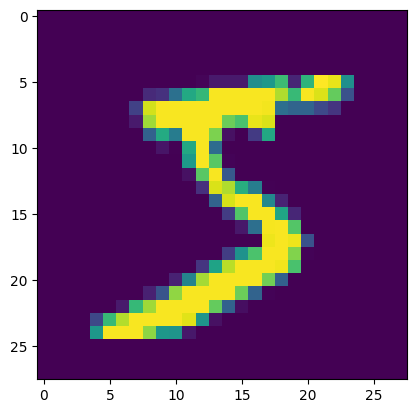

In [53]:
import sys, os
import numpy as np
from dataset.mnist import load_mnist
from PIL import Image
import matplotlib.pyplot as plt

def img_show(img):
  pil_img = Image.fromarray(np.uint8(img)) # PIL용 데이터 객체로 변환
  plt.imshow(pil_img)

(x_train, t_train), (x_test, t_test) = \
  load_mnist(flatten = True, normalize = False)

img = x_train[0]
label = t_train[0]
print(label) # 5

print(img.shape)          # (784,)
img = img.reshape(28, 28) # 원래 이미지의 모양으로 변형
print(img.shape)          # (28, 28)

img_show(img)

## 3.6.2 신경망의 추론 처리
### MNIST 데이터 셋을 가지고 추론을 수행하는 신경망 구현

- 입력층 뉴런 : 28 x 28 = 784 (이미지 크기)
- 출력층 뉴런 : 10 (0~9까지의 숫자)
- 은닉층 1 뉴런 : 50
- 은닉층 뉴런 2 : 100

**함수**
- init_network() : pickle 파일인 sample_weight.pkl에 저장된 '학습된 가중치 매개변수'를 읽어옴
- get_data() : mnist데이터를 읽어옴
- predict(network, x) : 신경망 순전파

> load_mnist의 인수인 normalize를 True로 - 데이터를 특정 범위로 변환하는 처리를 **정규화**라고 함
>
> **전처리** : 입력 데이터에 특정 변환을 가하는 작업

In [54]:
import pickle
def get_data():
  (x_train, t_train), (x_test, t_test) = \
    load_mnist(normalize=True, flatten=True, one_hot_label=False)

  return x_test, t_test

def init_network():
  with open("ch03/sample_weight.pkl", 'rb') as f:
    network = pickle.load(f)

  return network

def predict(network, x):
  W1, W2, W3 = network[ 'W1'], network['W2'], network['W3']
  b1, b2, b3 = network['b1'], network['b2'], network['b3']

  a1 = np.dot(x, W1) + b1
  z1 = sigmoid(a1)
  a2 = np.dot(z1, W2) + b2
  z2 = sigmoid(a2)
  a3 = np.dot(z2, W3) + b3
  y = softmax(a3)

  return y

x, t = get_data()
network = init_network()

accuracy_cnt = 0
for i in range(len(x)):
  y = predict(network, x[i])
  p = np.argmax(y) # 확률이 가장 높은 원소의 인덱스를 얻는다.
  if p == t[i]:
    accuracy_cnt += 1

print("Accuracy:" + str(float(accuracy_cnt) / len(x)))

Accuracy:0.9352


## 3.6.3 배치 처리

In [55]:
x, _ = get_data()
network = init_network()
W1, W2, W3 = network['W1'], network['W2'], network['W3']

print(x.shape)
print(x[0].shape)
print(W1.shape)
print(W2.shape)
print(W3.shape)

(10000, 784)
(784,)
(784, 50)
(50, 100)
(100, 10)


- 신경망 배열의 형상이 잘 맞춰진 걸 알 수 있음
### 입력에 이미지 여러 장을 넘기면?
x = 100 x 10, y = 100 x 10
> 이처럼 하나로 묶은 입력 데이터를 **배치, batch**라고 함

In [56]:
x, t = get_data()
network = init_network()

batch_size = 100 # 배치 크기
accuracy_cnt = 0

for i in range(0, len(x), batch_size):
  x_batch = x[i:i+batch_size]
  y_batch = predict(network, x_batch)
  p = np. argmax(y_batch, axis=1)
  accuracy_cnt += np. sum(p == t[i:i+batch_size])

print("Accuracy:" + str(float(accuracy_cnt) / len(x)))

Accuracy:0.9352


```
for i in range(0, len(x), batch_size):
  x_batch = x[i:i+batch_size]
```
위 코드를 이용해서 입력데이터를 묶음

```
p = np. argmax(y_batch, axis=1)
```
axis=1을 이용해서 100x10 중 1번째 차원을 구성하는 각 원소에서 최댓값의 인덱스를 찾게 함
```
accuracy_cnt += np. sum(p == t[i:i+batch_size])
```
bool 배열을 만들어 True의 개수를 더함


In [57]:
x = np.array([[0.1, 0.8, 0.1], [0.3, 0.1, 0.6],
[0.2, 0.5, 0.3], [0.8, 0.1, 0.1]])
y = np.argmax(x, axis=1)
print(y)

[1 2 1 0]


# 3.7 정리
- 신경망의 순전파를 공부함
- 활성화 함수 : 시그모이드 함수, 계단함수 공부함